# Fascicle Tutorial: Reading a Real BIDS Dataset

This notebook demonstrates Fascicle's core `DatasetManager` against
**real** MRI data, not a synthetic fixture: downloading one real scan,
pointing a `DatasetManager` at it with zero config, loading it with the
default (nibabel) loader, then swapping in a different loader (ANTsPy)
with no change to path resolution.

We use [`ds000114`](https://openneuro.org/datasets/ds000114), Gorgolewski
et al.'s classic 8-subject test-retest dataset, commonly used in BIDS and
Nipype tutorials — but we only download one subject's anatomical scan (a
few MB), not the whole dataset.

**Setup**: run `pip install -e ".[examples]"` from the repo root first —
this notebook needs `openneuro-py`, `matplotlib`, `jupyter`, and
`antspyx`, none of which fascicle itself depends on.

## 1. Download the dataset

Just `sub-01`'s anatomical folder — not the full dataset.

In [1]:
import openneuro as on

DATASET = "ds000114"
DATA_DIR = "data/ds000114"

on.download(
    dataset=DATASET,
    target_dir=DATA_DIR,
    include=[
        "sub-01/ses-test/anat",
        "sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz",
        "dataset_description.json",
    ],
)


👋 Hello! This is openneuro-py 2026.7.1. Great to see you! 🤗

   👉 Please report problems 🤯 and bugs 🪲 at
      https://github.com/openneuro-py/openneuro-py/issues



🌍 Preparing to download ds000114 …


📥 Checking 5 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds000114 (downloaded 0 files and 0 B).
 


🧠 Please enjoy your brains.
 


## 2. Point a `DatasetManager` at it

No config file needed — just the dataset folder.

In [2]:
from fascicle import DatasetManager

dm = DatasetManager(DATA_DIR)
dm.get_subjects()

['01']

## 3. Load with the default reader (nibabel)

`DatasetManager` registers `"T1w"` out of the box, read by file extension
with nibabel. Any other BIDS suffix is one line: `dm.bids_namer("bold")`
builds `bold` paths from BIDS entities, and leaving the reader out means
"read by file extension" -- nibabel again (see
[test_manager.py](../tests/test_manager.py) for the same pattern as a
unit test).

In [3]:
path = dm.get_path("01", "T1w", session="test")
img = dm.load("01", "T1w", session="test")

dm.add_datatype("bold", "raw", dm.bids_namer("bold"))
bold_path = dm.get_path("01", "bold", session="test", task="fingerfootlips")
bold_img = dm.load("01", "bold", session="test", task="fingerfootlips")

(path, type(img), img.shape), (bold_path, type(bold_img), bold_img.shape)

((PosixPath('/home/nino/Code/fascicle/examples/data/ds000114/sub-01/ses-test/anat/sub-01_ses-test_T1w.nii.gz'),
  nibabel.nifti1.Nifti1Image,
  (256, 156, 256)),
 (PosixPath('/home/nino/Code/fascicle/examples/data/ds000114/sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz'),
  nibabel.nifti1.Nifti1Image,
  (64, 64, 30, 184)))

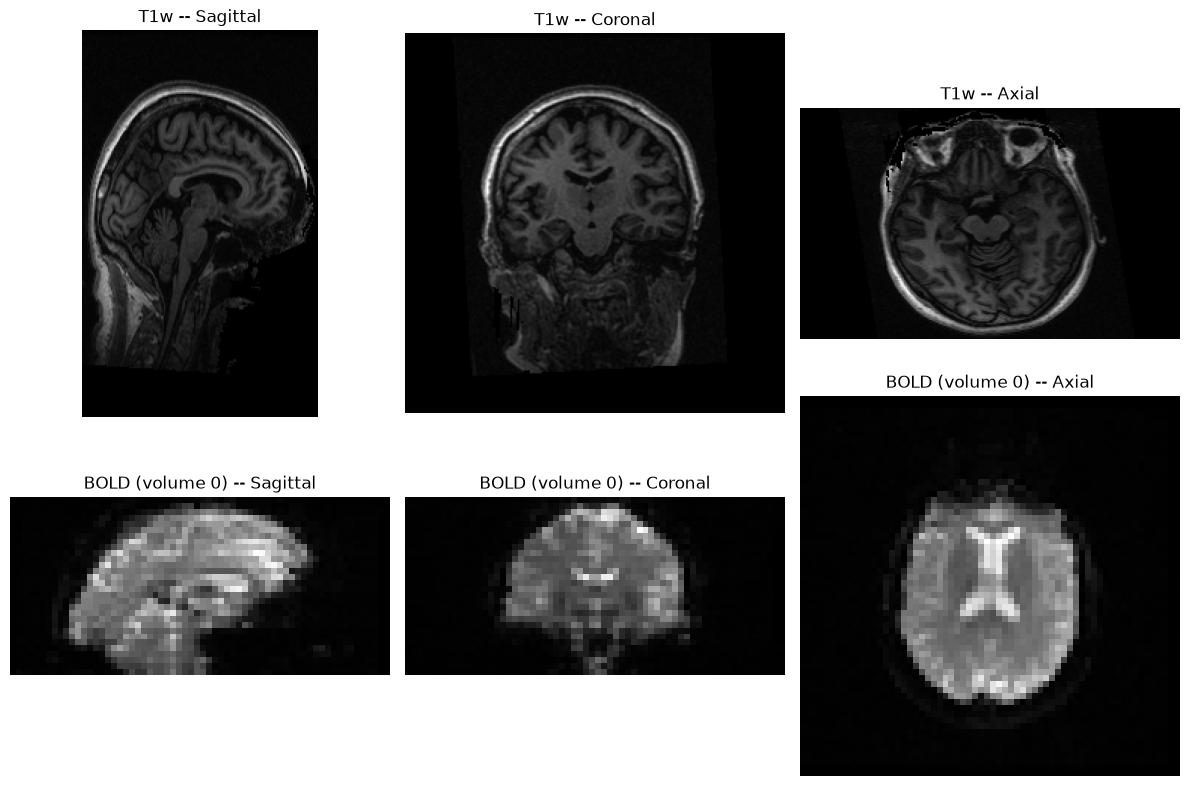

In [4]:
import matplotlib.pyplot as plt

t1_data = img.get_fdata()
t1_mid = [s // 2 for s in t1_data.shape]

# First BOLD volume of the run, mid-brain slices.
bold_data = bold_img.get_fdata()[..., 0]
bold_mid = [s // 2 for s in bold_data.shape]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, view in zip(axes[0], ("Sagittal", "Coronal", "Axial")):
    ax.set_title(f"T1w -- {view}")
axes[0, 0].imshow(t1_data[t1_mid[0], :, :].T, cmap="gray", origin="lower")
axes[0, 1].imshow(t1_data[:, t1_mid[1], :].T, cmap="gray", origin="lower")
axes[0, 2].imshow(t1_data[:, :, t1_mid[2]].T, cmap="gray", origin="lower")

for ax, view in zip(axes[1], ("Sagittal", "Coronal", "Axial")):
    ax.set_title(f"BOLD (volume 0) -- {view}")
axes[1, 0].imshow(bold_data[bold_mid[0], :, :].T, cmap="gray", origin="lower")
axes[1, 1].imshow(bold_data[:, bold_mid[1], :].T, cmap="gray", origin="lower")
axes[1, 2].imshow(bold_data[:, :, bold_mid[2]].T, cmap="gray", origin="lower")

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Load T1w with a custom reader (ANTsPy)

Each datatype keeps "how to name the file" (its namer) separate from "how
to read it" (its reader) and "how to write it" (its writer). Switching to
a different imaging library only replaces the reader with `set_reader` --
path naming (BIDS entities, subject/session) is untouched.

To switch *every* NIfTI read at once instead (raw BIDS, FreeSurfer,
charm, ...), use `dm.add_extension(".nii.gz", reader=ants_reader)`.

In [5]:
import ants


def ants_reader(path):
    return ants.image_read(str(path))


dm.set_reader("T1w", ants_reader)

img_ants = dm.load("01", "T1w", session="test")
type(img_ants)

ants.core.ants_image.ANTsImage

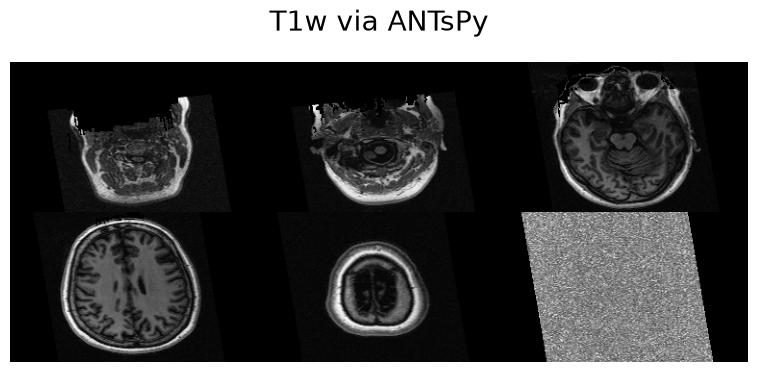

In [6]:
ants.plot(img_ants, axis=2, nslices=6, ncol=3, title="T1w via ANTsPy")